# Часть 1 Бустинг 

В этой части будем предсказывать зарплату data scientist-ов в зависимости  от ряда факторов с помощью градиентного бустинга.

В датасете есть следующие признаки:



* work_year: The number of years of work experience in the field of data science.

* experience_level: The level of experience, such as Junior, Senior, or Lead.

* employment_type: The type of employment, such as Full-time or Contract.

* job_title: The specific job title or role, such as Data Analyst or Data Scientist.

* salary: The salary amount for the given job.

* salary_currency: The currency in which the salary is denoted.

* salary_in_usd: The equivalent salary amount converted to US dollars (USD) for comparison purposes.

* employee_residence: The country or region where the employee resides.

* remote_ratio: The percentage of remote work offered in the job.

* company_location: The location of the company or organization.

* company_size: The company's size is categorized as Small, Medium, or Large.

In [ ]:
import pandas as pd

df = pd.read_csv("ds_salaries.csv")
df.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,SE,FT,Principal Data Scientist,80000,EUR,85847,ES,100,ES,L
1,2023,MI,CT,ML Engineer,30000,USD,30000,US,100,US,S
2,2023,MI,CT,ML Engineer,25500,USD,25500,US,100,US,S
3,2023,SE,FT,Data Scientist,175000,USD,175000,CA,100,CA,M
4,2023,SE,FT,Data Scientist,120000,USD,120000,CA,100,CA,M


## 1 Подготовка



*   Разделю выборку на train, val, test (80%, 10%, 10%)
*   Беру salary_in_usd в качестве таргета
*   Удаляю признак, из-за которого возможен лик в данных


In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns= ['salary_in_usd', 'salary'])
y = df['salary_in_usd']
X_train1, X_test, y_train1, y_test = train_test_split(X, y, random_state=0, test_size=0.1)
X_train, X_val, y_train, y_val = train_test_split(X_train1, y_train1, random_state=0, test_size=(1/9))

## 2 Линейная модель


*   Кодировка категориальных  признаки с помощью OneHotEncoder
*   Обучаю модель линейной регрессии
*   Оцениваю  качество через MAPE и RMSE


In [ ]:
import numpy as np
from xgboost.sklearn import XGBRegressor
import time

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder

cat_features = ['experience_level', 'employment_type', 'job_title', 'salary_currency', 'employee_residence', 'company_location', 'company_size' ]
num_features = ['work_year', 'remote_ratio']
Xn_train = np.array(X_train[num_features])
Xn_val = np.array(X_val[num_features])
Xn_test = np.array(X_test[num_features])

en = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
Xc_train = en.fit_transform(X_train[cat_features])
Xc_val = en.transform(X_val[cat_features])
Xc_test = en.transform(X_test[cat_features])

X_tr = np.hstack([Xn_train, Xc_train])
X_vl = np.hstack([Xn_val, Xc_val])
X_ts = np.hstack([Xn_test, Xc_test])

lr = LinearRegression()
lr.fit(X_tr, y_train)
y_vpred = lr.predict(X_vl)

print('MAPE: ', mean_absolute_percentage_error(y_val, y_vpred))
print('RMSE: ', (mean_squared_error(y_val, y_vpred))**0.5)

MAPE:  0.4188792890271572
RMSE:  44736.00313266626


##  3  XGboost

Начнем с библиотеки xgboost.

Обучаю модель `XGBRegressor` на тех же данных, что линейную модель, подобрав оптимальные гиперпараметры (`max_depth, learning_rate, n_estimators, gamma`, etc.) по валидационной выборке. Оцениваю качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [ ]:
from xgboost.sklearn import XGBRegressor
params = {
    'max_depth' : [15, 17, 19] ,
    'learning_rate' : [0.1, 0.15, 0.2],
    'n_estimators' :  [100, 125, 175],
    'gamma' : [0, 0.001, 0.005, 0.1, 1]
}
best_rmse = 10**10
best_mape = 10**10
for i in params['max_depth']:
  for j in params['learning_rate']:
    for k in params['n_estimators']:
      for m in params['gamma']:
        xgb = XGBRegressor(max_depth = i, learning_rate = j, n_estimators = k, gamma = m)
        xgb.fit(X_tr, y_train)
        y_pr = xgb.predict(X_vl)
        mape = (mean_absolute_percentage_error(y_val, y_pr))
        rmse = ((mean_squared_error(y_val, y_pr))**0.5)
        if best_mape > mape:
          best_rmse = rmse
          best_mape = mape
          i1, j1, k1, m1 = i, j, k, m
print(i1, j1, k1, m1)
print(best_mape, best_rmse)

17 0.15 100 0
0.35813063383102417 43113.10223122433


In [ ]:
print(i1, j1, k1, m1) #  еще такие запуски были. то есть  макс глубина 17 взято и остальные не по приколу.
print(best_mape, best_rmse) # мы выбрали mape основным и видим что он проигрывает конечно всего на 1 процентр но проигрывает

9 0.1 300 0
0.36841046810150146 43196.97026412848


In [ ]:
print(i1, j1, k1, m1) #до этого запускала немного с другими парметрами, уперлось в максимум, поэтоу решила увеличить глубину и кол-во деревьев
print(best_mape, best_rmse)

17 0.15 125 0
0.35883787274360657 43159.46987626238


In [ ]:
xgb = XGBRegressor(max_depth = 17, learning_rate = 0.15, n_estimators = 125, gamma = 0)
start1 = time.time()
xgb.fit(X_tr, y_train)
end1 = time.time()
start2 = time.time()
y_pr = xgb.predict(X_vl)
end2 = time.time()

In [ ]:
print('время обучения', end1 - start1)
print('скорость предсказания', end2 - start2)

время обучения 0.47997236251831055
скорость предсказания 0.006304502487182617


In [ ]:
print('MAPE: ', (mean_absolute_percentage_error(y_val, y_pr))  )
print('RMSE: ', ((mean_squared_error(y_val, y_pr))**0.5) )

MAPE:  0.35883787274360657
RMSE:  43159.46987626238


Обучили модель на лучших параметрах, которые были подобраны перебором по mape. скорость обучения модели полсекунды(0.49 сек), предсказания примерно 8 миллисекунд. Но несмотря на то, что подбирали лучшие параметры и попробовали 300 моделей всеразличных, значения средней относительной ошибки около 35%, а корень из среднего квадратичной ошибки около 43 тысяч usd.

##  4 CatBoost

Теперь библиотека CatBoost.

Обучаю модель `CatBoostRegressor`, подобрав оптимальные гиперпараметры (`depth, learning_rate, iterations`, etc.) по валидационной выборке. Оцените качество итоговой модели (MAPE, RMSE), скорость обучения и скорость предсказания.

In [ ]:
!pip install --upgrade catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.8 MB/s eta 0:00:00


In [ ]:
from catboost import *

In [ ]:
from catboost import CatBoostRegressor
params = {
    'depth' : [1, 2, 4],
    'learning_rate' : [0.01, 0.03, 0.05],
    'iterations' : [1500, 1750, 2000],
}
best_rmse = 10**10
best_mape = 10**10
for i in params['depth']:
  for j in params['learning_rate']:
    for k in params['iterations']:
      cat = CatBoostRegressor(depth=i, learning_rate=j, iterations=k)
      cat.fit(X_tr, y_train, verbose=False)
      y_pr_val = cat.predict(X_vl)
      mape = (mean_absolute_percentage_error(y_val, y_pr_val))
      rmse = ((mean_squared_error(y_val, y_pr_val))**0.5)
      if best_mape > mape:
        best_rmse = rmse
        best_mape = mape
        i1, j1, k1, = i, j, k
print(i1, j1, k1)
print(best_mape, best_rmse)

1 0.05 1750
0.3773077721898956 42303.177493095325


In [ ]:
cat = CatBoostRegressor(depth=1, learning_rate=0.05, iterations=1750)
start1 = time.time()
cat.fit(X_tr, y_train, verbose=False)
end1 = time.time()
start2 = time.time()
y_pr_val = cat.predict(X_vl)
end2 = time.time()
print('время обучения', end1 - start1)
print('скорость предсказания', end2 - start2)

время обучения 0.9273812770843506
скорость предсказания 0.003481626510620117


In [ ]:
print('MAPE: ', (mean_absolute_percentage_error(y_val, y_pr_val)))
print('RMSE: ', ((mean_squared_error(y_val, y_pr_val))**0.5))

MAPE:  0.3773077721898956
RMSE:  42303.177493095325


пока проигрывает предыдущей модели, и по mape и по скорости обучения, тут 0.9 секнуды, но предсказвает быстро - 0.003

Обучаю catboost с подбором оптимальных гиперпараметров снова, используя pool для передачи данных в модель с указанием какие признаки категориальные, а какие нет с помощью параметра cat_features. Оцениваю качество и время. 

In [ ]:
pool=Pool(X_train, label=y_train, cat_features=cat_features)
eval_pool = Pool(X_val, y_val, cat_features=cat_features)

In [ ]:
best_rmse = 10**10
best_mape = 10**10
for i in params['depth']:
  for j in params['learning_rate']:
    for k in params['iterations']:
      cat = CatBoostRegressor(depth=i, learning_rate=j, iterations=k, verbose=False)
      cat.fit(pool, eval_set = eval_pool)
      y_pr_val = cat.predict(eval_pool)
      mape = (mean_absolute_percentage_error(y_val, y_pr_val))
      rmse = ((mean_squared_error(y_val, y_pr_val))**0.5)
      if best_mape > mape:
        best_rmse = rmse
        best_mape = mape
        i1, j1, k1 = i, j, k
print(i1, j1, k1)
print(best_mape, best_rmse)

2 0.03 1500
0.3615522655076785 41948.09823850062


In [ ]:
cat = CatBoostRegressor(depth=2, learning_rate=0.03, iterations=1500)
start1 = time.time()
cat.fit(pool, eval_set = eval_pool,verbose=False)
end1 = time.time()
start2 = time.time()
y_pr_val = cat.predict(eval_pool)
end2 = time.time()
print('время обучения', end1 - start1)
print('скорость предсказания', end2 - start2)

время обучения 1.8819715976715088
скорость предсказания 0.0019636154174804688


 мы можем заметить, что модель catboost при обработке категориальных признаков самостоятельно, гораздо дольше обучается, в отличии когда передаем признаки уже готовые, где категориальные закодированы OneHotEncoder. но стоит учитывать, что "ручная" обработка занимает значительно больше времени, чем одна секунда, на которую и увеличивается время обучения. также за счет того, что у catboost обработка категориальных сильная сторона, она уменьшает ошибки rmse и mape в отлчии от модели catboost где кодировали категориальные самостоятельно.

тем самым с использованием cat_features улучшилось качество предсказаний, но увеличилось время обучения.

##  5  LightGBM

И библиотека LightGBM - использую `LGBMRegressor`


In [ ]:
from lightgbm import LGBMRegressor
params = {
    'max_depth' : [7, 9, 12, 15, 17] ,
    'learning_rate' : [0.05, 0.1, 0.15],
    'n_estimators' :  [125, 175, 250, 300],
}
best_rmse = 10**10
best_mape = 10**10
for i in params['max_depth']:
  for j in params['learning_rate']:
    for k in params['n_estimators']:
      gbm = LGBMRegressor(max_depth = i, learning_rate = j, n_estimators = k)
      gbm.fit(X_tr, y_train)
      y_pr = gbm.predict(X_vl)
      mape = (mean_absolute_percentage_error(y_val, y_pr))
      rmse = ((mean_squared_error(y_val, y_pr))**0.5)
      if best_mape > mape:
        best_rmse = rmse
        best_mape = mape
        i1, j1, k1 = i, j, k
print(i1, j1, k1)
print(best_mape, best_rmse)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000648 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000615 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (56 outputs left out)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000628 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000900 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000700 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000626 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
9 0.05 175
0.3640195384815856 42486.50953414231


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
gbm = LGBMRegressor(max_depth = 9, learning_rate = 0.05, n_estimators = 175)
start1 = time.time()
gbm.fit(X_tr, y_train)
end1 = time.time()
start2 = time.time()
y_pr = gbm.predict(X_vl)
end2 = time.time()

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000825 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 3003, number of used features: 41
[LightGBM] [Info] Start training from score 137929.457209
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
print('время обучения', end1 - start1)
print('скорость предсказания', end2 - start2)
print('MAPE: ', (mean_absolute_percentage_error(y_val, y_pr)) )
print('RMSE: ', ((mean_squared_error(y_val, y_pr))**0.5))

время обучения 0.11938762664794922
скорость предсказания 0.01048731803894043
MAPE:  0.3640195384815856
RMSE:  42486.50953414231


## Задание 6  Сравнение и выводы

 Лучший результат по средней относительной ошибке показала модель XGBoost 0.359, то есть ошибка около 36%. Худший результат по MAPE показала модель CatBoost - 37%, когда категориальные признаки были закодированы OneHotEncoder, что может быть логично, так как одной из сильных сторон этой модели является то. что она оптимизировна для работы с категориальными признаками и не нужны их обрабатывать самостоятельно перед обучением.

Лучший результат по корню из средней квадратичной ошибки у модели CatBoost - 41948.10, где мы через cat_features подаем ей информацию о том какиме иименно признаки категориальные. Худшее RMSE наблюдаем же у LightGBM и у XGBoost около 43-х тысяч с разницей в несколько сотен.

Время обучения самое маленькое у LightGBM около 0.1-0.09 , самое длинное же у CatBoost(которая обрабатывает категориальные признаки самостоятельно) ~1.8, что логично и справедливо, остальные модели быстрее обучаются, но в то же время на кодировку категориальных через OneHotEncoder мы потратим больше времени(так как это отдельная кодировка, котрую еще необходимо задать и прописать, и только потом уже подать обработанные данные в модель).

Время предсказания в основном у всех моделей достаточно маленькое, тем более, что при каждом запуске оно немного меняется, но CatBoost(с кодировкой в модели) на несколько милисекунд быстрее остальных. предсказаание оеоло 1 миллисекунды занимает, а дольше всех предсказывает GBM около 0.01 секунд.


У XGBoost было подорбрано 4 гиперпараметра: максимальная глубина дерева, размер шага, количество деревьев (итераций) и параметр гамма (минимальное улучшение которое должно давать разделение).

В ходе пдбора парметров предпочли строить достаточно глубокие деревья для бустинга - 17 с шаг 0.15(влиянием), количество деревьев (итераций по улучшению) - 125, а параметр гамма оказался бесполезным, то есть не стали вводить ограничения на улучшения для разбиения. так же можно сделать вывод что модель может быть склонна к переобучению, так как gamma = 0 (что может давать глубокие и сложные модели), а также глубина максимальная 17.

на модели CatBoost лучшими параметрами стали макс глубина 1, достаточно маленький шаг 0.05 и количество итераций превышает XGBoost более чем в ~10 раз - 1750 , но это и логично, так как мы взяли решающие пни для работы. то есть тут больше итераций по улучшению, но сами модели маленькие по глубине.

Для CatBoost который сам обрабатывал категориальные признаки - уже деревья с глубиной два, количество итераций соотвественно меньше хоть и незначительно - 1500, шаг изменения тоже уменьшился с 0.05 стал 0.03.

Для LightGBM было подобрано 3 гиперапараметра (по смыслу такие же как и у XGBoost:max_depth = 9, learning_rate = 0.05, n_estimators = 175. то есть модель показала себя лучше на среднем между параметрами для XGBoost CatBoost: 2 и 17.



# Часть 2 Кластеризация 

Будем работать с данными о том, каких исполнителей слушают пользователи музыкального сервиса.

Каждая строка таблицы - информация об одном пользователе. Каждый столбец - это исполнитель (The Beatles, Radiohead, etc.)

Для каждой пары (пользователь, исполнитель) в таблице стоит число - доля прослушивания этого исполнителя этим пользователем.


In [ ]:
import pandas as pd
ratings = pd.read_excel("https://github.com/evgpat/edu_stepik_rec_sys/blob/main/datasets/sample_matrix.xlsx?raw=true", engine='openpyxl')
ratings.head()

,user,the beatles,radiohead,deathcab for cutie,coldplay,modest mouse,sufjan stevens,dylan. bob,red hot clili peppers,pink fluid,...,municipal waste,townes van zandt,curtis mayfield,jewel,lamb,michal w. smith,群星,agalloch,meshuggah,yellowcard
0,0,NaN,0.020417,NaN,NaN,NaN,NaN,NaN,0.030496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0.184962,0.024561,NaN,NaN,0.136341,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,0.028635,NaN,NaN,NaN,0.024559,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.043529,0.086281,0.034590,0.016712,0.015935,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
ratings.shape()

Будем строить кластеризацию исполнителей: если двух исполнителей слушало много людей примерно одинаковую долю своего времени (то есть векторы близки в пространстве), то, возможно исполнители похожи. Эта информация может быть полезна при построении рекомендательных систем.

##  1 (0.5 балла) Подготовка

Транспонируем матрицу ratings, чтобы по строкам стояли исполнители.

In [ ]:
ratings = ratings.T

In [ ]:
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
user,0.000000,1.000000,2.000000,3.0,4.000000,5.000000,6.0,7.0,8.000000,9.000000,...,4990.000000,4991.0,4992.000000,4993.000000,4994.000000,4995.000000,4996.0,4997.000000,4998.0,4999.000000
the beatles,NaN,NaN,NaN,NaN,0.043529,NaN,NaN,NaN,0.093398,0.017621,...,NaN,NaN,0.121169,0.038168,0.007939,0.017884,NaN,0.076923,NaN,NaN
radiohead,0.020417,0.184962,NaN,NaN,0.086281,0.006322,NaN,NaN,NaN,0.019156,...,0.017735,NaN,NaN,NaN,0.011187,NaN,NaN,NaN,NaN,NaN
deathcab for cutie,NaN,0.024561,0.028635,NaN,0.034590,NaN,NaN,NaN,NaN,0.013349,...,0.121344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.027893
coldplay,NaN,NaN,NaN,NaN,0.016712,NaN,NaN,NaN,NaN,NaN,...,0.217175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Убираем строку под названием `user`.

In [ ]:
ratings = ratings.drop('user')
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,NaN,NaN,NaN,NaN,0.043529,NaN,NaN,NaN,0.093398,0.017621,...,NaN,NaN,0.121169,0.038168,0.007939,0.017884,NaN,0.076923,NaN,NaN
radiohead,0.020417,0.184962,NaN,NaN,0.086281,0.006322,NaN,NaN,NaN,0.019156,...,0.017735,NaN,NaN,NaN,0.011187,NaN,NaN,NaN,NaN,NaN
deathcab for cutie,NaN,0.024561,0.028635,NaN,0.034590,NaN,NaN,NaN,NaN,0.013349,...,0.121344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.027893
coldplay,NaN,NaN,NaN,NaN,0.016712,NaN,NaN,NaN,NaN,NaN,...,0.217175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
modest mouse,NaN,NaN,NaN,NaN,0.015935,NaN,NaN,NaN,NaN,0.030437,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В таблице много пропусков, так как пользователи слушают не всех-всех исполнителей, чья музыка представлена в сервисе, а некоторое подмножество (обычно около 30 исполнителей)


Доля исполнителя в музыке, прослушанной  пользователем, равна 0, если пользователь никогда не слушал музыку данного музыканта, поэтому заполняем пропуски нулями.



In [ ]:
ratings = ratings.fillna(0)
ratings.sample()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
margot and the nuclear so and sos,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.030333


In [ ]:
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
the beatles,0.000000,0.000000,0.000000,0.0,0.043529,0.000000,0.0,0.0,0.093398,0.017621,...,0.000000,0.0,0.121169,0.038168,0.007939,0.017884,0.0,0.076923,0.0,0.000000
radiohead,0.020417,0.184962,0.000000,0.0,0.086281,0.006322,0.0,0.0,0.000000,0.019156,...,0.017735,0.0,0.000000,0.000000,0.011187,0.000000,0.0,0.000000,0.0,0.000000
deathcab for cutie,0.000000,0.024561,0.028635,0.0,0.034590,0.000000,0.0,0.0,0.000000,0.013349,...,0.121344,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.027893
coldplay,0.000000,0.000000,0.000000,0.0,0.016712,0.000000,0.0,0.0,0.000000,0.000000,...,0.217175,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000
modest mouse,0.000000,0.000000,0.000000,0.0,0.015935,0.000000,0.0,0.0,0.000000,0.030437,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000


##  2  Первая кластеризация

Применяем KMeans с 5ю кластерами, сохраняем полученные лейблы

In [ ]:
from sklearn.cluster import KMeans

k_means = KMeans(n_clusters=5, random_state = 400)
k_means = k_means.fit(ratings)
clusters1 = k_means.predict(ratings)

Вывожу размеры кластеров. 

In [ ]:
from collections import Counter
counter = Counter(k_means.labels_)
print(counter)

Counter({np.int32(0): 996, np.int32(2): 1, np.int32(4): 1, np.int32(3): 1, np.int32(1): 1})


кластеризация получилось бесполезной.

возможно такое произошло из-за сильного перекоса в данных. то есть какие-то 4 исполнителя сильно отличаются от остальных 996 и от друг друга, потому что их меньше всего слушают или большего всего слушают, так как мы оцениваем с точки зрения доли прослушиваний.

In [ ]:
group = pd.DataFrame({'group': ratings.index, 'cluster': k_means.labels_})
group

,group,cluster
0,the beatles,2
1,radiohead,0
2,deathcab for cutie,0
3,coldplay,0
4,modest mouse,0
...,...,...
995,michal w. smith,0
996,群星,0
997,agalloch,0
998,meshuggah,0


## Задание 3 (0.5 балла) Объяснение результатов

При кластеризации получилось $\geq 1$ кластера размера 1. Вывожу исполнителей, которые составляют такие кластеры. 

In [ ]:
c1 = group[group['cluster'] == 1]
c2 = group[group['cluster'] == 2]
c3 = group[group['cluster'] == 3]
c4 = group[group['cluster'] == 4]

In [ ]:
print(c1)
print(c2)
print(c3)
print(c4)

      group  cluster
148  mogwai        1
         group  cluster
0  the beatles        2
               group  cluster
125  brritney spears        3
       group  cluster
80  paramore        4


In [ ]:
df = pd.DataFrame()
df['доля пользователей'] = (ratings > 0).mean(axis=1)
df['средняя доля'] = ratings.mean(axis=1)
df['средняя доля среди слущающих'] = ratings[ratings > 0].mean(axis=1)
df.loc['the beatles']

,the beatles
доля пользователей,0.334200
средняя доля,0.018369
средняя доля среди слущающих,0.054964


In [ ]:
df.loc['brritney spears']

,brritney spears
доля пользователей,0.049200
средняя доля,0.003115
средняя доля среди слущающих,0.063314


In [ ]:
df.loc['mogwai']

,mogwai
доля пользователей,0.044200
средняя доля,0.001672
средняя доля среди слущающих,0.037833


In [ ]:
df.loc['paramore']

,paramore
доля пользователей,0.061000
средняя доля,0.002246
средняя доля среди слущающих,0.036816


The Beatles сильно выделяется так как из всего списка 33% пользователй хоть раз слушали их, это достатчно большая группа пользователей, то есть каждый третий из датасета. а также в связи с этим средняя доля прослушивания The Beatles  среди всех пользователей (среди всех кто слушал и не слушал то есть 0) составляет 2%, что достаточно много и отличает от остальных группах в других кластерах у которых меньше 1 процента доля среди всех.

##  4  Улучшение кластеризации

Попытаемся избавиться от этой проблемы: нормализуем данные при помощи `normalize`.

In [ ]:
from sklearn.preprocessing import normalize

nratings = normalize(ratings)
nratings

array([[0.        , 0.        , 0.        , ..., 0.02130159, 0.        ,
        0.        ],
       [0.00934824, 0.08468808, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.0172781 , 0.02014407, ..., 0.        , 0.        ,
        0.01962161],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

Применим KMeans с 5ю кластерами на преобразованной матрице, посмотрим на их размеры.

In [ ]:
kmeans = KMeans(n_clusters=5, random_state = 400)
kmeans = kmeans.fit(nratings)
clusters2 = kmeans.predict(nratings)

In [ ]:
counter = Counter(kmeans.labels_)
print(counter)

Counter({np.int32(2): 433, np.int32(0): 211, np.int32(4): 203, np.int32(1): 79, np.int32(3): 74})


 по результатам видно, что распределение по кластерам стало более сбалансированным, один кластер конечно включает в себя почти половину музыкальных исполнителей (433), но у нас уже нет 'выбросов' и 'шума'как в первом распрелении, где было 4 кластера с одним объектом

## Задание 6 (1 балл) Визуализация

Хотелось бы как-то визуализировать полученную кластеризацию. Построим точечные графики `plt.scatter` для нескольких пар признаков исполнителей, покрасив точки в цвета кластеров. 

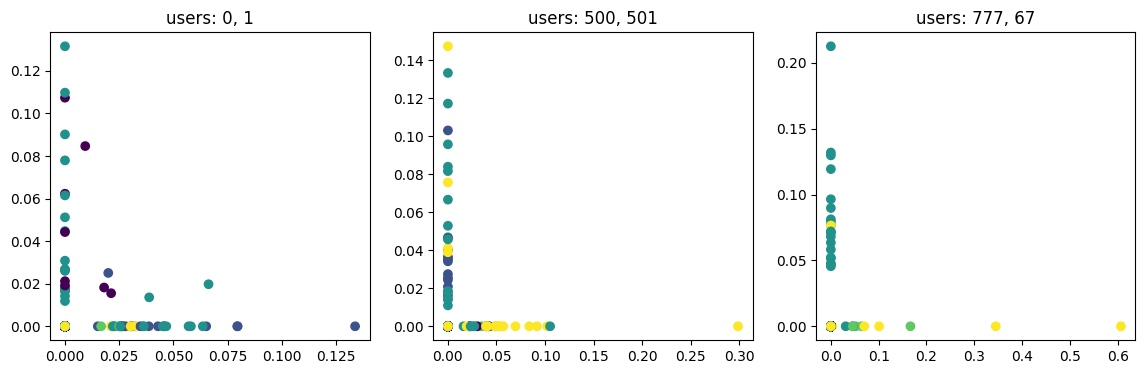

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize= (14,4))
pair = [(0, 1), (500, 501), (777, 67)]
for k, (i, j) in enumerate(pair):
  plt.subplot(1, 3, k+1)
  plt.scatter(nratings[:,i], nratings[:,j], c = clusters2)
  plt.title('users' + ': ' + str(i) + ', '+ str(j))

у нас 5000 пользователей по прослушиваниям которых мы делали кластеризацию, а графики мы строим по двум случайным пользователям (да я их задала сама но по сути они случайные) и то есть по двум слушателям, хотя предсказания были основаны на 5000 мы не сможем заметить какую-то законнморность, то есть какое-то видное распределение. у нас просто хаотичное распредлеение.

Для визуализации данных высокой размерности возьмем метод t-SNE (стохастическое вложение соседей с t-распределением). Данный метод является нелинейным методом снижения размерности: каждый объект высокой размерности будет моделироваться объектов более низкой (например, 2) размерности таким образом, чтобы похожие объекты моделировались близкими, непохожие - далекими с большой вероятностью.

Применим `TSNE` из библиотеки `sklearn` и визуализируйте полученные объекты, покрасив их в цвета их кластеров

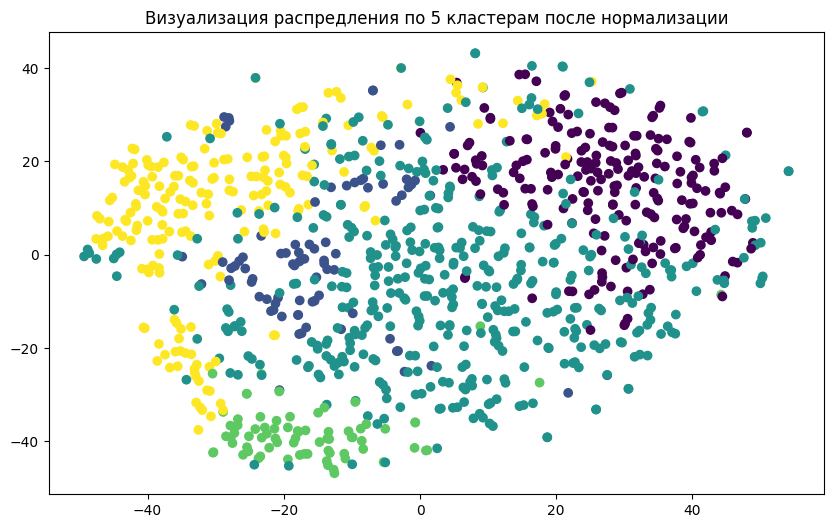

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components = 2)
nratings2 = tsne.fit_transform(nratings)
plt.figure(figsize= (10,6))
plt.scatter(nratings2[:,0], nratings2[:,1], c = clusters2)
plt.title('Визуализация распредления по 5 кластерам после нормализации')
plt.show()

## Задание 7 (1 балл) Подбор гиперпараметров

Подберите оптимальное количество кластеров (максимум 100 кластеров) с использованием индекса Силуэта. Зафиксируйте `random_state=42`

In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np
best_k, best_score = 0, -1
for k in range(2, 101):
    k_means = KMeans(n_clusters = k, random_state = 42)
    k_means = k_means.fit(nratings)
    clusters = k_means.predict(nratings)
    score = np.round(silhouette_score(X=nratings, labels=clusters), 2)
    if score > best_score:
      best_score = score
      best_k = k
print('best score', best_score)
print('best k', best_k)

best score 0.01
best k 3


Сделаем t-SNE визуализацию полученной кластеризации.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state = 42)
kmeans = kmeans.fit(nratings)
clusters3 = kmeans.predict(nratings)

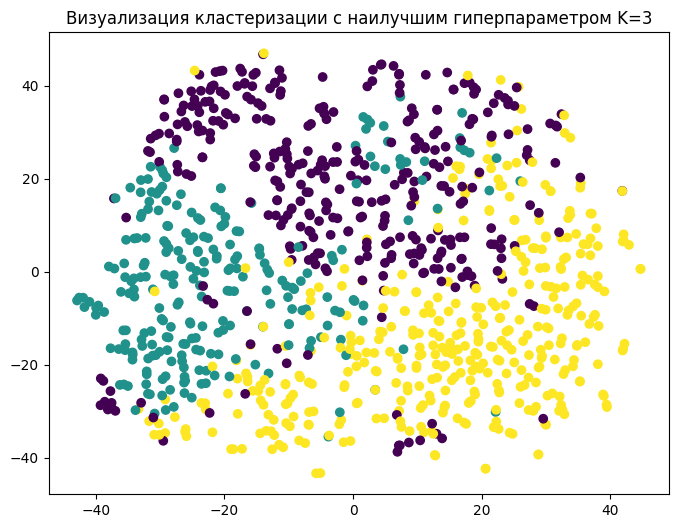

In [ ]:
plt.figure(figsize= (8,6))
plt.scatter(nratings2[:,0], nratings2[:,1], c = clusters3)
plt.title('Визуализация кластеризации с наилучшим гиперпараметром K=3')
plt.show()

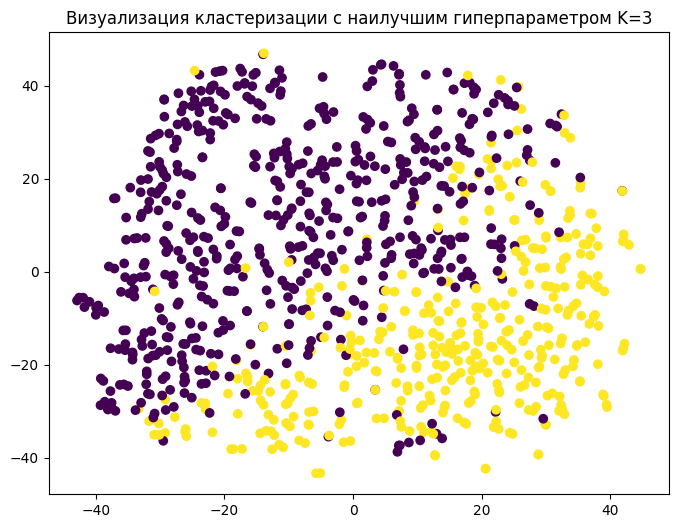

In [ ]:
plt.figure(figsize= (8,6))
plt.scatter(nratings2[:,0], nratings2[:,1], c = (clusters3 == 2))
plt.title('Визуализация кластера 2 (желтый)')
plt.show()

 вообще кластеров получилось немного k=3 и для визуализации тоже вполне хорошее число,но у точек достаточно плотное расположение, так что закрасить один кластер одним цветом. а остальные другим - достаточно полезная идея для визуализации. на графике я выбрала дла закрашивания кластер = 2, мне показался он более интересным, так как у него хорошо видно распределение, он концентрируется в правом нижнем углу, у остальнх же кластеров четкое расположение на графике менее выражено.